# 02 · Control charts

**Case study 7: cutting unplanned downtime on a machine fleet** · Phase 4b, notebook 2 of 3

Notebook 01 showed that each component has a sensor signature in the two days before it fails. This notebook puts that on **control charts**, the standard statistical process control (SPC) tool. A control chart tracks a measurement over time against limits that show the normal range for that machine. A point outside the limits is a signal that something has changed.

Inputs: the raw telemetry, failures and maintenance in `data/raw/`. Outputs: charts in `images/`.

> The dataset is synthetic. Findings show what this method would reveal on real plant data.

In [1]:
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))
import pdm
from pdm import INK, INK_2, MUTED, AXIS, GRID, SERIES, CRITICAL, SENSORS, SENSOR_LABEL, COMPONENTS

pdm.set_style()

## 1. How the limits are set

For every machine and every sensor:

| Part of the chart | Definition |
| --- | --- |
| Plotted value | Daily mean: the rolling mean of the last 24 hourly readings |
| Centre line | Mean of the daily mean during the machine's **baseline** |
| Control limits | Centre line ± 3 standard deviations (σ) of the daily mean during the baseline |
| Baseline | First 30 days of 2015, minus the 7 days before and 2 days after any failure |

Two choices worth explaining:

- **Limits per machine.** Machines differ, so one fleet-wide limit would flag normal machines and miss changes on others. Each machine is compared with its own normal.
- **σ from the standard deviation, not the moving range.** A textbook individuals chart estimates σ from the average moving range between consecutive points. Consecutive 24-hour rolling means share 23 of their 24 readings, so their moving range is tiny and the limits would be far too tight. The standard deviation of the baseline daily means gives honest limits.

The limits come only from January, so the rest of the year is a fair test of them.

In [2]:
raw = pdm.load_raw()
tel, failures, maint = raw["telemetry"], raw["failures"], raw["maint"]
events = pdm.failure_events(failures)

tel = pdm.add_daily_mean(tel)
limits = pdm.baseline_limits(tel, events)
tel = pdm.add_z(tel, limits)
limits.describe().round(2).loc[["mean", "min", "max"]]

,machine_id,volt_mean,volt_sd,rotate_mean,rotate_sd,pressure_mean,pressure_sd,vibration_mean,vibration_sd,baseline_hours
mean,50.5,170.61,3.81,448.02,12.96,100.59,3.36,40.21,1.39,549.52
min,1.0,168.86,2.19,433.95,7.71,98.96,1.44,39.55,0.71,265.00
max,100.0,174.32,7.91,456.18,29.66,104.43,8.63,42.03,4.26,697.00


## 2. One machine, one sensor, one year

The chart below follows vibration on the machine with the most comp4 failures. comp4 is the component whose failures vibration warns about (notebook 01).

In [3]:
comp4 = failures[failures["comp"] == "comp4"]
showcase = comp4["machine_id"].value_counts().idxmax()
print(f"Machine {showcase}: {(comp4['machine_id'] == showcase).sum()} comp4 failures, "
      f"{(failures['machine_id'] == showcase).sum()} component failures in total")

Machine 37: 6 comp4 failures, 14 component failures in total


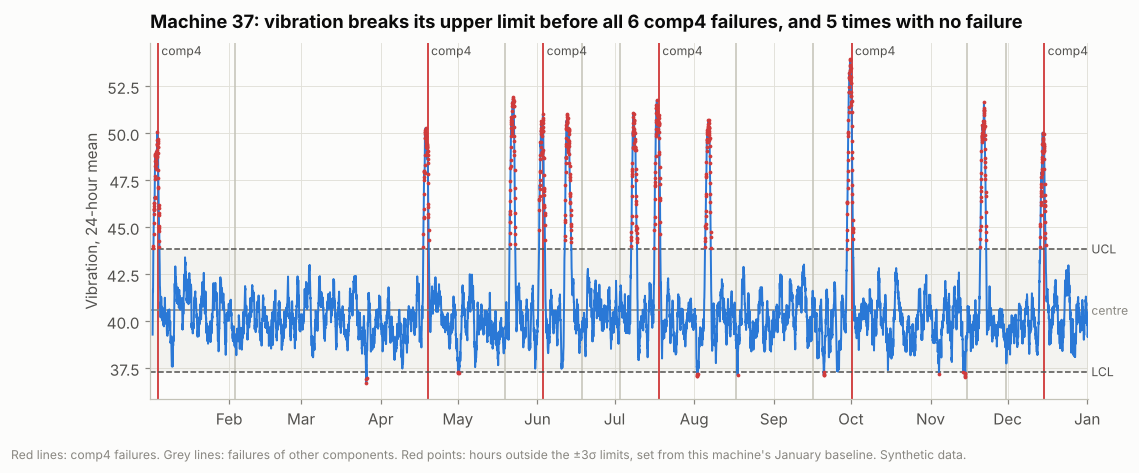

Excursions above the UCL: 11, followed by a comp4 failure within 7 days: 6, false alarms: 5


{'centre': np.float64(40.585301829637665),
 'ucl': np.float64(43.85201815982416),
 'lcl': np.float64(37.31858549945117),
 'out_hours': 633}

In [4]:
def control_chart(ax, machine, sensor, start=None, end=None, signature_comp=None, label_failures=True):
    """Daily mean of one sensor on one machine, with centre line, ±3σ limits and failures."""
    d = tel[tel["machine_id"] == machine]
    if start is not None:
        d = d[(d["datetime"] >= start) & (d["datetime"] < end)]
    lim = limits.set_index("machine_id").loc[machine]
    mu, sd = lim[f"{sensor}_mean"], lim[f"{sensor}_sd"]
    ucl, lcl = mu + 3 * sd, mu - 3 * sd
    y = d[f"{sensor}_24h"]

    ax.axhspan(lcl, ucl, color=AXIS, alpha=0.15, linewidth=0)
    ax.axhline(mu, color=MUTED, linewidth=1)
    for v in (ucl, lcl):
        ax.axhline(v, color=INK_2, linewidth=1, linestyle="--")
    ax.plot(d["datetime"], y, color=SERIES[0], linewidth=1.3)
    out = (y > ucl) | (y < lcl)
    ax.scatter(d.loc[out, "datetime"], y[out], color=CRITICAL, s=6, zorder=3, linewidth=0)

    f = failures[(failures["machine_id"] == machine)
                 & (failures["datetime"] >= d["datetime"].min()) & (failures["datetime"] <= d["datetime"].max())]
    top = ax.get_ylim()[1]
    for r in f.itertuples():
        main = signature_comp is None or r.comp == signature_comp
        ax.axvline(r.datetime, color=CRITICAL if main else AXIS, linewidth=1.2 if main else 1, zorder=1)
        if label_failures and main:
            ax.text(r.datetime, top, f" {r.comp}", color=INK_2, fontsize=8, va="top", ha="left")
    ax.set_xlim(d["datetime"].min(), d["datetime"].max())
    return dict(centre=mu, ucl=ucl, lcl=lcl, out_hours=int(out.sum()))

fig, ax = plt.subplots(figsize=(11, 4.2))
info = control_chart(ax, showcase, "vibration", signature_comp="comp4")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_ylabel("Vibration, 24-hour mean")
# count separate excursions above the UCL (alerts merged within 7 days) and how many led to a comp4 failure
d37 = tel[tel["machine_id"] == showcase].reset_index(drop=True)
exc = pdm.alerts_from_flag(d37, d37["vibration_z"] > 3, min_hours=1, merge_days=7)
exc, _ = pdm.match_alerts(exc, comp4[comp4["machine_id"] == showcase].reset_index(drop=True))
n_true, n_false = int(exc["is_true"].sum()), int((~exc["is_true"]).sum())
ax.set_title(f"Machine {showcase}: vibration breaks its upper limit before all {n_true} comp4 failures, "
             f"and {n_false} times with no failure")
xr = ax.get_xlim()
ax.text(xr[1], info["ucl"], " UCL", color=INK_2, fontsize=8, va="center")
ax.text(xr[1], info["centre"], " centre", color=MUTED, fontsize=8, va="center")
ax.text(xr[1], info["lcl"], " LCL", color=INK_2, fontsize=8, va="center")
fig.text(0.01, -0.02, "Red lines: comp4 failures. Grey lines: failures of other components. Red points: hours outside the ±3σ limits, "
         "set from this machine's January baseline. Synthetic data.", color=MUTED, fontsize=8)
pdm.save(fig, f"control_chart_vibration_machine{showcase}.png")
plt.show()
print(f"Excursions above the UCL: {len(exc)}, followed by a comp4 failure within 7 days: {n_true}, false alarms: {n_false}")
info

## 3. All four sensors around failures of different components

Another machine, every sensor, over a 90-day window that contains failures of all four components. Each sensor reacts to its own component, and only to it. Some excursions are not followed by any failure.

In [5]:
# the 90-day window on any machine with the most distinct failed components (ties: most failures)
best = None
for m, g in failures.groupby("machine_id"):
    for start in pd.date_range("2015-01-15", "2015-10-01", freq="7D"):
        w = g[(g["datetime"] >= start) & (g["datetime"] < start + pd.Timedelta(days=90))]
        key = (w["comp"].nunique(), len(w))
        if best is None or key > best[0]:
            best = (key, m, start)
(_, n_failures), zoom_machine, zoom_start = best
zoom_end = zoom_start + pd.Timedelta(days=90)
print(f"Machine {zoom_machine}, {zoom_start:%d %b} to {zoom_end:%d %b}: "
      f"{best[0][0]} components, {n_failures} failures")
failures[(failures["machine_id"] == zoom_machine) & failures["datetime"].between(zoom_start, zoom_end)]

Machine 98, 02 Apr to 01 Jul: 4 components, 8 failures


,datetime,machine_id,comp
726,2015-04-15 06:00:00,98,comp3
727,2015-04-30 06:00:00,98,comp2
728,2015-04-30 06:00:00,98,comp4
729,2015-05-15 06:00:00,98,comp1
730,2015-05-30 06:00:00,98,comp3
731,2015-06-14 06:00:00,98,comp2
732,2015-06-29 06:00:00,98,comp1
733,2015-06-29 06:00:00,98,comp4


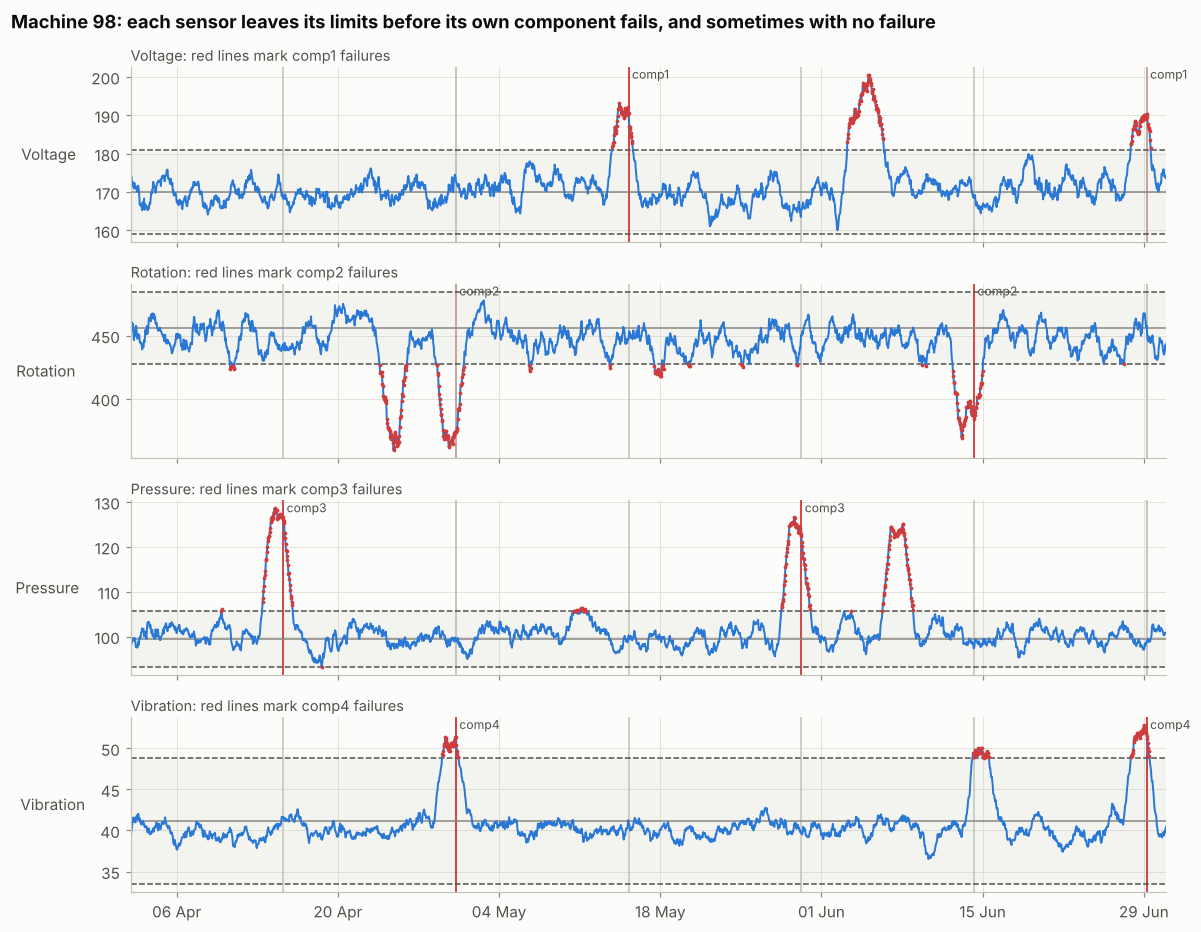

In [6]:
signature = {"volt": "comp1", "rotate": "comp2", "pressure": "comp3", "vibration": "comp4"}
fig, axes = plt.subplots(4, 1, figsize=(11, 8.6), sharex=True)
for ax, s in zip(axes, SENSORS):
    control_chart(ax, zoom_machine, s, zoom_start, zoom_end, signature_comp=signature[s])
    ax.set_ylabel(SENSOR_LABEL[s], rotation=0, ha="right", va="center", labelpad=10)
    ax.set_title(f"{SENSOR_LABEL[s]}: red lines mark {signature[s]} failures", fontsize=9.5,
                 fontweight="normal", color=INK_2, loc="left", pad=4)
axes[-1].xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0, interval=2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
fig.suptitle(f"Machine {zoom_machine}: each sensor leaves its limits before its own component fails, and sometimes with no failure",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
pdm.save(fig, f"control_charts_4_sensors_machine{zoom_machine}.png")
plt.show()

## 4. How often is a machine out of control, and how often does that mean a failure?

An out-of-limit point is only useful if it usually comes before a failure. For each sensor, count the machine-hours beyond its limit **in the direction of its signature** (up for voltage, pressure and vibration; down for rotation). Then check what share of them fall in the 48 hours before a failure of that sensor's component. Hours in the 48 hours after any part replacement are left out: the daily mean still includes readings from before the repair.

In [7]:
direction = {"volt": 1, "rotate": -1, "pressure": 1, "vibration": 1}
since_rep = pdm.hours_since_replacement(tel, maint)
settled = ~(since_rep < 48)          # NaN (no replacement yet) counts as settled
valid = tel["volt_z"].notna().values & settled

# machine-hours that fall in the 48 h before a failure of each component
pre = {}
for c in COMPONENTS:
    f = failures[failures["comp"] == c][["machine_id", "datetime"]]
    marks = pd.concat([f.assign(datetime=f["datetime"] - pd.Timedelta(hours=h)) for h in range(1, 49)])
    pre[c] = tel[["machine_id", "datetime"]].merge(marks.assign(hit=True), how="left",
                                                   on=["machine_id", "datetime"])["hit"].notna().values

rows = []
for s in SENSORS:
    z = direction[s] * tel[f"{s}_z"].values
    out = (z > 3) & valid
    rows.append({
        "sensor": s,
        "signature_component": signature[s],
        "hours_out_of_control": int(out.sum()),
        "pct_of_machine_hours": round(100 * out.sum() / valid.sum(), 2),
        "pct_in_48h_before_its_component_fails": round(100 * (out & pre[signature[s]]).sum() / out.sum(), 1),
    })
ooc = pd.DataFrame(rows)
ooc

,sensor,signature_component,hours_out_of_control,pct_of_machine_hours,pct_in_48h_before_its_component_fails
0,volt,comp1,25518,3.31,23.1
1,rotate,comp2,30192,3.92,28.2
2,pressure,comp3,29119,3.78,15.8
3,vibration,comp4,30859,4.00,21.1


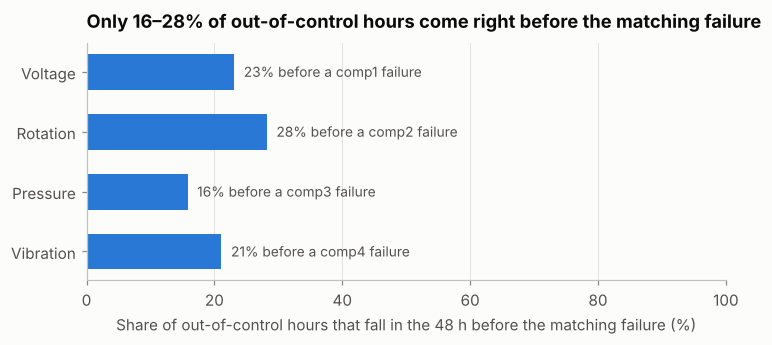

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 2.8))
o = ooc.iloc[::-1]
ax.barh([SENSOR_LABEL[s] for s in o["sensor"]], o["pct_in_48h_before_its_component_fails"],
        color=SERIES[0], height=0.6)
for y, (v, c) in enumerate(zip(o["pct_in_48h_before_its_component_fails"], o["signature_component"])):
    ax.text(v + 1.5, y, f"{v:.0f}% before a {c} failure", va="center", color=INK_2, fontsize=9)
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of out-of-control hours that fall in the 48 h before the matching failure (%)")
ax.set_title("Only 16–28% of out-of-control hours come right before the matching failure")
pdm.save(fig, "control_chart_signal_share.png")
plt.show()

## Findings

- **Control limits work as an early warning.** Daily-mean voltage, rotation, pressure and vibration leave each machine's own ±3σ limits in the day or two before their matching component fails. The limits are set from January alone, so the other eleven months test them fairly.
- **Each sensor speaks for one component.** Voltage for comp1, rotation for comp2, pressure for comp3 and vibration for comp4. A plant would route each alarm to the right part and the right technician.
- **But control limits alone raise many false alarms.** Each sensor is outside its limits for 3–4% of machine-hours, and only 16–28% of those hours fall in the 48 hours before the matching failure. On machine 37 in section 2, a third or more of the vibration excursions led to no failure, and no part was replaced around them either. Part of this is the limits themselves: they come from one month, so they are on the tight side. Part of it is real noise: a reading can drift for a day and recover.
- **So a good alert needs more than one signal.** Notebook 03 turns the control charts into alert rules, adds the error codes from the SQL analysis, and measures the trade-off: how many failures a rule catches (recall), how many of its alerts are real (precision), and how much notice it gives.